# MLIP
Short, independent practice codes on the building blocks of machine-learned interatomic potentials.

| # | Exercise | Key idea |
|---|---|---|
| 1 | Dimer energy and force, finite-difference check | $\mathbf F=-\nabla E$ |
| 2 | Cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ | descriptor as a smooth RDF |
| 4 | Angular function $G^4$ versus bond angle | angular resolution, $\lambda$ and $\zeta$ |

Units are Lennard-Jones reduced units ($\epsilon=\sigma=1$). Only NumPy and Matplotlib are needed.

---
## Exercise 1. Dimer energy and force
$U(r)=4\left[r^{-12}-r^{-6}\right]$, force on atom 2 along the bond $F=-dU/dr$. Check the analytic force against the central difference $-[U(r+h)-U(r-h)]/2h$.

In [24]:
import numpy as np

U  = lambda r: 4 * (r**-12 - r**-6)
dU = lambda r: 4 * (-12 * r**-13 + 6 * r**-7)

h = 1e-5
for r in (0.95, 1.12, 1.5, 2.0):
    F_analytic = -dU(r)
    F_numeric  = -(U(r + h) - U(r - h)) / (2 * h)
    print(f"r = {r:4.2f}  U = {U(r):+8.4f}  F = {F_analytic:+9.4f}  |diff| = {abs(F_analytic - F_numeric):.1e}")

print("minimum at r_m = 2^(1/6) =", round(2**(1/6), 4), " U(r_m) =", round(U(2**(1/6)), 4))

r = 0.95  U =  +1.9610  F =  +59.1376  |diff| = 2.8e-07
r = 1.12  U =  -0.9998  F =   +0.1440  |diff| = 1.9e-08
r = 1.50  U =  -0.3203  F =   -1.1580  |diff| = 2.6e-10
r = 2.00  U =  -0.0615  F =   -0.1816  |diff| = 4.0e-11
minimum at r_m = 2^(1/6) = 1.1225  U(r_m) = -1.0


**Your turn.** Replace the potential by a Morse potential $U=(1-e^{-2(r-1)})^2-1$ and its derivative. Where is the force zero?

### Solution 1: Morse potential

$$U(r)=\left(1-e^{-2(r-1)}\right)^2-1,\qquad
\frac{dU}{dr}=4e^{-2(r-1)}\left(1-e^{-2(r-1)}\right),\qquad F=-\frac{dU}{dr}.$$

**Where is the force zero?** $F=0$ requires $e^{-2(r-1)}=1$ (the other factor, $e^{-2(r-1)}$, never vanishes at finite $r$), so $r-1=0$, i.e. **$r_0=1$**, where $U(r_0)=-1$ is the well depth. For $r<1$ the force is positive (repulsive); for $r>1$ it is negative (attractive) and decays to zero as $r\to\infty$ (dissociation). The curvature at the minimum is $U''(1)=8$, which sets the vibrational stiffness. Unlike Lennard-Jones, the Morse repulsion stays finite at $r=0$.

r = 0.80  U =  -0.7581  F =   +2.9349  |diff| = 2.0e-09
r = 0.95  U =  -0.9889  F =   +0.4649  |diff| = 1.0e-09
r = 1.00  U =  -1.0000  F =   -0.0000  |diff| = 8.0e-10
r = 1.12  U =  -0.9545  F =   -0.6714  |diff| = 4.4e-10
r = 1.50  U =  -0.6004  F =   -0.9302  |diff| = 4.2e-11
r = 2.00  U =  -0.2524  F =   -0.4681  |diff| = 2.3e-11

Force is zero at r = 1.000000, U(r0) = -1.000000
U''(r_min): Morse = 8.000, LJ = 57.146


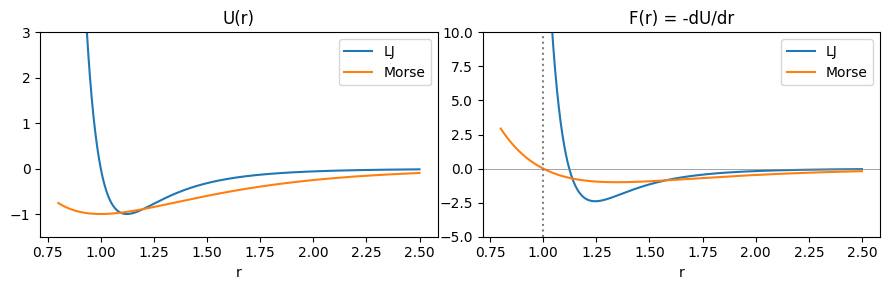

In [25]:
import matplotlib.pyplot as plt

Um  = lambda r: (1 - np.exp(-2*(r - 1)))**2 - 1
dUm = lambda r: 4*np.exp(-2*(r - 1)) * (1 - np.exp(-2*(r - 1)))

h = 1e-5
for r in (0.8, 0.95, 1.0, 1.12, 1.5, 2.0):
    F_analytic = -dUm(r)
    F_numeric  = -(Um(r + h) - Um(r - h)) / (2*h)
    print(f"r = {r:4.2f}  U = {Um(r):+8.4f}  F = {F_analytic:+9.4f}  |diff| = {abs(F_analytic - F_numeric):.1e}")

# locate the zero of the force numerically (bisection on dU/dr) and compare with the analytic r = 1
lo, hi = 0.5, 2.0
for _ in range(60):
    mid = 0.5*(lo + hi)
    if dUm(lo)*dUm(mid) <= 0: hi = mid
    else: lo = mid
r0 = 0.5*(lo + hi)
print(f"\nForce is zero at r = {r0:.6f}, U(r0) = {Um(r0):.6f}")
assert abs(r0 - 1) < 1e-8 and abs(Um(r0) + 1) < 1e-12

# curvature at the minimum (second derivative by central difference) and comparison with Lennard-Jones
k_morse = (Um(1 + 1e-4) - 2*Um(1.0) + Um(1 - 1e-4)) / 1e-8
rm = 2**(1/6)
k_lj = (U(rm + 1e-4) - 2*U(rm) + U(rm - 1e-4)) / 1e-8
print(f"U''(r_min): Morse = {k_morse:.3f}, LJ = {k_lj:.3f}")

rr = np.linspace(0.8, 2.5, 400)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(rr, U(rr), label="LJ"); ax[0].plot(rr, Um(rr), label="Morse")
ax[0].set_ylim(-1.5, 3); ax[0].set_title("U(r)"); ax[0].legend()
ax[1].plot(rr, -dU(rr), label="LJ"); ax[1].plot(rr, -dUm(rr), label="Morse")
ax[1].axhline(0, color="gray", lw=0.5); ax[1].axvline(1, color="gray", ls=":")
ax[1].set_ylim(-5, 10); ax[1].set_title("F(r) = -dU/dr"); ax[1].legend()
for a in ax: a.set_xlabel("r")
plt.tight_layout(); plt.show()

---
## Exercise 2. Cutoff functions
A hard cutoff makes the energy jump when an atom crosses $r_c$. Compare a hard step, the cosine cutoff and the polynomial envelope ($p=6$) by plotting $f$ and $df/dr$.

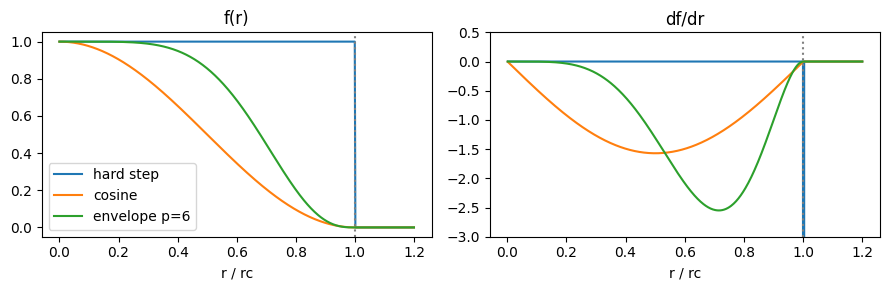

In [26]:
import numpy as np, matplotlib.pyplot as plt

rc = 1.0
r = np.linspace(0, 1.2, 600)
x = np.minimum(r / rc, 1)
hard   = (r < rc).astype(float)
cosine = np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0)
p = 6
env    = np.where(r < rc, 1 - 28 * x**p + 48 * x**(p + 1) - 21 * x**(p + 2), 0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for f, name in [(hard, "hard step"), (cosine, "cosine"), (env, "envelope p=6")]:
    ax[0].plot(r, f, label=name)
    ax[1].plot(r[1:], np.diff(f) / np.diff(r), label=name)
ax[0].set_title("f(r)"); ax[1].set_title("df/dr"); ax[1].set_ylim(-3, 0.5)
for a in ax: a.axvline(rc, color="gray", ls=":"); a.set_xlabel("r / rc")
ax[0].legend(); plt.tight_layout(); plt.show()

**Your turn.** The hard step's derivative is a spike (a delta function) at $r_c$. What would that mean for the force on an atom crossing the cutoff during MD?

### Solution 2: what a delta-function derivative means

The force on an atom is $F=-\nabla E$, so with a hard step $f(r)=\Theta(r_c-r)$ the force contains $-\,U(r_c)\,\delta(r-r_c)$ along the bond: an **infinite, instantaneous kick** at the cutoff radius, while the energy itself **jumps** by $U(r_c)$. During MD this means:

* the energy is **not conserved**: the potential energy changes discontinuously while the kinetic energy is not adjusted, so the total energy drifts every time a pair crosses $r_c$ (and the drift is systematic, not random);
* the integrator (velocity Verlet) samples forces only at discrete times, so the force is either missed or inserted as a large impulse depending on the time step; trajectories become time-step dependent and noisy;
* temperature/pressure estimates are biased, and the potential is not differentiable, so ML training on forces is ill-posed.

Smooth cutoffs fix this. The cosine cutoff has $f(r_c)=0$ and $f'(r_c)=0$ (continuous energy and force), but its second derivative jumps. The polynomial envelope with $p=6$ has $f$, $f'$ and $f''$ all zero at $r_c$ (check: at $x=1$, $1-28+48-21=0$; $-168+336-168=0$; $-840+2016-1176=0$), so energies, forces and their derivatives are continuous.

The simulation below sends one particle outward through $r=r_c$ in a Lennard-Jones potential and compares energy conservation for a hard cutoff and a smooth (cosine-multiplied) one.

hard cutoff   : max |E - E0| = 0.0163   (jump U(rc) = 0.0163)
smooth cutoff : max |E - E0| = 2.6e-07


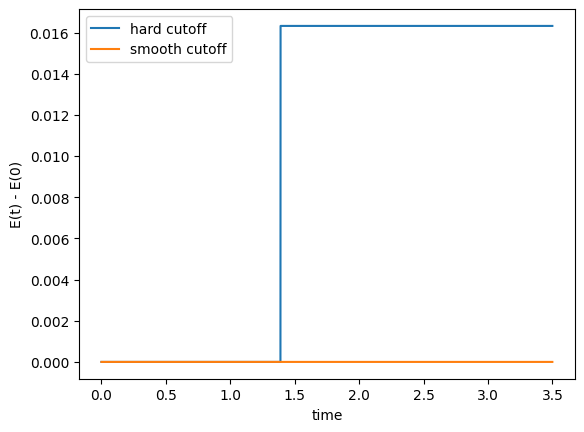

In [27]:
rc_md = 2.5
fc_  = lambda r: np.where(r < rc_md, 0.5*(np.cos(np.pi*r/rc_md) + 1), 0.0)
dfc_ = lambda r: np.where(r < rc_md, -0.5*np.pi/rc_md*np.sin(np.pi*r/rc_md), 0.0)

V_hard = lambda r: np.where(r < rc_md, U(r), 0.0)
F_hard = lambda r: np.where(r < rc_md, -dU(r), 0.0)
V_smooth = lambda r: U(r)*fc_(r)
F_smooth = lambda r: -(dU(r)*fc_(r) + U(r)*dfc_(r))

def run(V, F, r0=1.5, v0=1.0, dt=1e-3, steps=3500):
    r, v = r0, v0
    E = []
    f = F(r)
    for _ in range(steps):                  # velocity Verlet, unit (reduced) mass
        v += 0.5*dt*f
        r += dt*v
        f = F(r)
        v += 0.5*dt*f
        E.append(0.5*v**2 + V(r))
    return np.array(E)

E_hard, E_smooth = run(V_hard, F_hard), run(V_smooth, F_smooth)
print(f"hard cutoff   : max |E - E0| = {np.max(np.abs(E_hard - E_hard[0])):.4f}   (jump U(rc) = {-U(rc_md):.4f})")
print(f"smooth cutoff : max |E - E0| = {np.max(np.abs(E_smooth - E_smooth[0])):.1e}")
t = np.arange(len(E_hard))*1e-3
plt.plot(t, E_hard - E_hard[0], label="hard cutoff"); plt.plot(t, E_smooth - E_smooth[0], label="smooth cutoff")
plt.xlabel("time"); plt.ylabel("E(t) - E(0)"); plt.legend(); plt.show()

---
## Exercise 3. A radial fingerprint
$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij})$. Scanning $R_s$ turns the neighbour list of atom $i$ into a smooth curve, essentially a broadened radial distribution function.

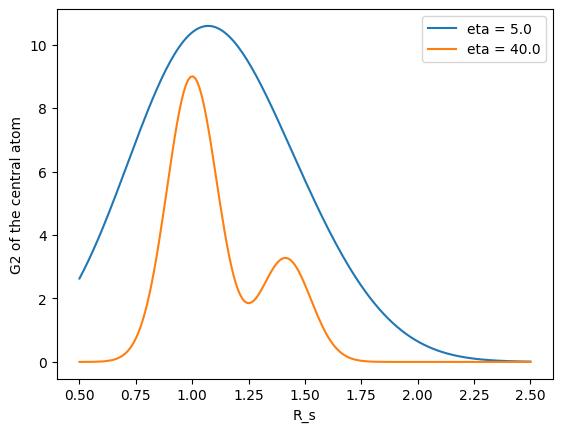

In [28]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

# atom 0 at the centre of a small fcc-like cluster: 12 neighbours at 1.0, 6 at 1.41
nn  = np.array([[1,1,0],[1,-1,0],[-1,1,0],[-1,-1,0],[1,0,1],[1,0,-1],
                [-1,0,1],[-1,0,-1],[0,1,1],[0,1,-1],[0,-1,1],[0,-1,-1]]) / np.sqrt(2)
nnn = np.array([[1,0,0],[-1,0,0],[0,1,0],[0,-1,0],[0,0,1],[0,0,-1]]) * np.sqrt(2)
R = np.vstack([[0, 0, 0], nn, nnn])

r0j = np.linalg.norm(R[1:] - R[0], axis=1)
Rs = np.linspace(0.5, 2.5, 200)
for eta in (5.0, 40.0):
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, 3.0)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}")
plt.xlabel("R_s"); plt.ylabel("G2 of the central atom"); plt.legend(); plt.show()

**Your turn.** Remove the 6 second-shell atoms. Which peak disappears? With $\eta=5$, can you still tell the two shells apart?

### Solution 3: removing the second shell

Removing the 6 second-shell atoms (at $r=\sqrt2\approx1.41$) deletes the **second peak, the one near $R_s\approx1.41$**; only the first-shell peak at $R_s=1$ (height $12\,f_c(1)=12\times0.75=9$) remains.

**Can the shells be separated with $\eta=5$?** No. A Gaussian of width $\sigma=1/\sqrt{2\eta}\approx0.32$ is comparable to the shell separation $0.41$, so the two Gaussians overlap into one broad bump (with the shell atoms combined, the maximum is a single peak near $R_s\approx1.07$, shifted towards the second shell). Only $\eta=40$ ($\sigma\approx0.11$) resolves two peaks at about 1.0 and 1.41. Large $\eta$ gives high radial resolution but needs more $R_s$ values (more descriptor components) to cover the cutoff sphere; small $\eta$ is a compact but blurred descriptor.

eta =  5.0: peaks with 2nd shell (R_s, G2) = [(1.073, 10.59)]
           peaks without 2nd shell      = [(1.003, 9.0)]
eta = 40.0: peaks with 2nd shell (R_s, G2) = [(1.003, 9.001), (1.415, 3.278)]
           peaks without 2nd shell      = [(1.003, 8.998)]


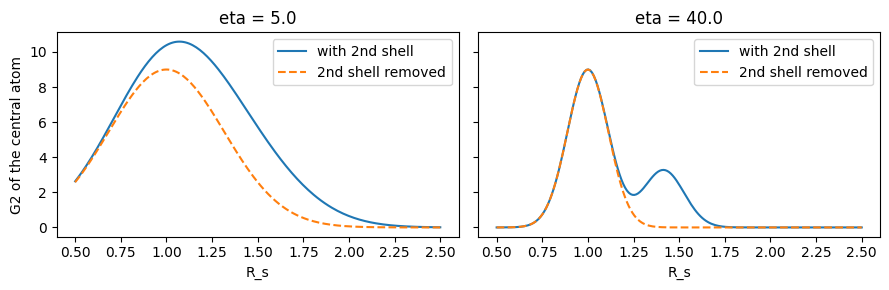

In [29]:
R_first = R[:13]                     # central atom + 12 first-shell neighbours only
r0j_first = np.linalg.norm(R_first[1:] - R_first[0], axis=1)

def G2_curve(r, eta, rc=3.0):
    return np.array([np.sum(np.exp(-eta*(r - s)**2)*fc(r, rc)) for s in Rs])

def peaks(y):
    i = np.where((y[1:-1] > y[:-2]) & (y[1:-1] >= y[2:]))[0] + 1
    return [(round(float(Rs[k]), 3), round(float(y[k]), 3)) for k in i]

fig, ax = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for a, eta in zip(ax, (5.0, 40.0)):
    full  = G2_curve(r0j, eta)
    first = G2_curve(r0j_first, eta)
    a.plot(Rs, full, label="with 2nd shell"); a.plot(Rs, first, "--", label="2nd shell removed")
    a.set_title(f"eta = {eta}"); a.set_xlabel("R_s"); a.legend()
    print(f"eta = {eta:4.1f}: peaks with 2nd shell (R_s, G2) = {peaks(full)}")
    print(f"           peaks without 2nd shell      = {peaks(first)}")
ax[0].set_ylabel("G2 of the central atom"); plt.tight_layout(); plt.show()

---
## Exercise 4. Angular function versus bond angle
For one triplet, $G^4\propto 2^{1-\zeta}(1+\lambda\cos\theta)^\zeta$ (the radial factors are constant if bond lengths are fixed). Plot the angular factor for several $\zeta$ and both $\lambda$, then recover $\theta$ from the ratio of the two $\lambda$ values: $(1-\cos\theta)/(1+\cos\theta)=\tan^2(\theta/2)$.

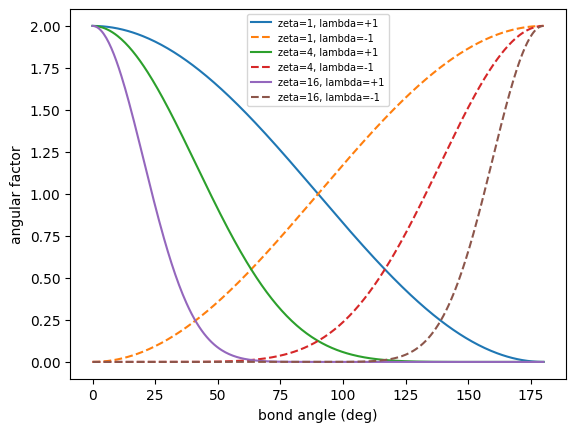

recovered angle: 104.5 deg


In [30]:
import numpy as np, matplotlib.pyplot as plt

theta = np.linspace(0, 180, 361)
c = np.cos(np.deg2rad(theta))
for zeta in (1, 4, 16):
    for lam, st in ((1, "-"), (-1, "--")):
        plt.plot(theta, 2**(1 - zeta) * (1 + lam * c)**zeta, st, label=f"zeta={zeta}, lambda={lam:+d}")
plt.xlabel("bond angle (deg)"); plt.ylabel("angular factor"); plt.legend(fontsize=7); plt.show()

# recover the angle of a single triplet from the two lambda values (zeta = 1)
true_angle = 104.5
cth = np.cos(np.deg2rad(true_angle))
ratio = (1 - cth) / (1 + cth)
print("recovered angle:", round(2 * np.degrees(np.arctan(np.sqrt(ratio))), 2), "deg")

**Your turn.** Which $\zeta$ would you use to distinguish $100^\circ$ from $110^\circ$? Compute $(1-\cos\theta)^\zeta$ at both angles for $\zeta=1$ and $\zeta=16$ and compare the relative difference.

### Solution 4: choosing $\zeta$ to separate $100^\circ$ from $110^\circ$

With $\lambda=-1$ the angular factor is proportional to $(1-\cos\theta)^\zeta$. Here $1-\cos100^\circ=1.1736$ and $1-\cos110^\circ=1.3420$, so the ratio is $1.1435$ and
* $\zeta=1$: values $1.174$ and $1.342$, relative difference **about 14%**;
* $\zeta=16$: values $\approx13.0$ and $\approx110.7$, relative difference **about 750%** ($1.1435^{16}\approx8.5$).

The relative difference grows roughly as $\zeta\,\Delta\ln(1-\cos\theta)$, so **a large $\zeta$ (around 16 here) gives much higher angular resolution** and should be chosen to distinguish such nearby angles. The trade-off is that a large $\zeta$ makes the function very sharply peaked (with $\lambda=-1$ it is negligible far from $180^\circ$; with $\lambda=+1$ far from $0^\circ$), so it only responds to angles near one end of the range, and each small error in the angle is amplified. In practice a set of several $\zeta$ and both $\lambda$ values is used so that low-$\zeta$ functions provide coarse coverage and high-$\zeta$ functions provide fine resolution.

#### cos = lambda deg: np.cos(np.deg2rad(deg))
a1, a2 = 100.0, 110.0
for zeta in (1, 16):
    v1 = (1 - cos(a1))**zeta
    v2 = (1 - cos(a2))**zeta
    print(f"zeta = {zeta:2d}: (1-cos)^zeta at {a1:.0f} deg = {v1:9.4f}, at {a2:.0f} deg = {v2:9.4f}, "
          f"ratio = {v2/v1:6.3f}, relative difference = {100*(v2/v1 - 1):7.1f} %")

### with the full factor 2^(1-zeta) (1 + lambda cos)^zeta the ratio is unchanged (a constant cancels)
zetas = np.arange(1, 33)
rel = ((1 - cos(a2))/(1 - cos(a1)))**zetas - 1
plt.plot(zetas, 100*rel, "o-"); plt.yscale("log")
plt.xlabel("zeta"); plt.ylabel("relative difference 110 vs 100 deg (%)"); plt.show()